In [1]:
!pip -q install datasets sentence-transformers chromadb pandas numpy scikit-learn matplotlib seaborn

In [2]:
!pip install -q -U datasets sentence-transformers chromadb seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.


In [3]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import islice
from datasets import load_dataset
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.metrics import precision_score, recall_score, f1_score
from IPython.display import display

import chromadb

sns.set_theme(style="whitegrid")
np.random.seed(5996)

In [4]:
DATASET_NAME = "ccdv/arxiv-summarization"
DATASET_CONFIG = "document"
N_DOCUMENTS = 100

streaming_dataset = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG,
    split="train",
    streaming=True
)

raw_rows = list(islice(streaming_dataset, N_DOCUMENTS))

print("Number of documents loaded:", len(raw_rows))
print("Available fields:", raw_rows[0].keys())

README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

Number of documents loaded: 100
Available fields: dict_keys(['article', 'abstract'])


In [5]:
def clean_text(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

documents = []

for index, row in enumerate(raw_rows):
    article = clean_text(row.get("article", ""))
    abstract = clean_text(row.get("abstract", ""))

    if article:
        documents.append({
            "doc_id": index,
            "article": article,
            "abstract": abstract
        })

documents_df = pd.DataFrame(documents)

print("Documents after preprocessing:", len(documents_df))
display(documents_df.head())

Documents after preprocessing: 100


,doc_id,article,abstract
0,0,additive models @xcite provide an important fa...,additive models play an important role in semi...
1,1,the leptonic decays of a charged pseudoscalar ...,"we have studied the leptonic decay @xmath0 , v..."
2,2,the transport properties of nonlinear non - eq...,"in 84 , 258 ( 2000 ) , mateos conjectured that..."
3,3,studies of laser beams propagating through tur...,the effect of a random phase diffuser on fluct...
4,4,the so - called `` nucleon spin crisis '' rais...,with a special intention of clarifying the und...


In [6]:
def fixed_word_chunks(text, chunk_size=180, overlap=40):
    words = text.split()
    chunks = []

    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]

        if len(chunk_words) < 20:
            continue

        chunks.append(" ".join(chunk_words))

    return chunks


def build_fixed_chunks(documents_df):
    all_chunks = []

    for _, row in documents_df.iterrows():
        chunks = fixed_word_chunks(row["article"])

        for chunk_number, chunk in enumerate(chunks):
            all_chunks.append({
                "chunk_id": f"fixed_{row['doc_id']}_{chunk_number}",
                "doc_id": int(row["doc_id"]),
                "text": chunk,
                "strategy": "fixed_word"
            })

    return pd.DataFrame(all_chunks)


fixed_chunks_df = build_fixed_chunks(documents_df)

print("Fixed-word chunks:", len(fixed_chunks_df))
display(fixed_chunks_df.head())

Fixed-word chunks: 4690


,chunk_id,doc_id,text,strategy
0,fixed_0_0,0,additive models @xcite provide an important fa...,fixed_word
1,fixed_0_1,0,", see e.g. @xcite , @xcite , @xcite , @xcite ,...",fixed_word
2,fixed_0_2,0,"and lipschitz continuous loss function , on a ...",fixed_word
3,fixed_0_3,0,on the lipschitz continuous but non - differen...,fixed_word
4,fixed_0_4,0,with a complete separable metric space @xmath3...,fixed_word


In [7]:
def split_into_sentences(text):
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [sentence.strip() for sentence in sentences if sentence.strip()]


def sentence_window_chunks(
    text,
    max_words=180,
    overlap_sentences=1
):
    sentences = split_into_sentences(text)
    chunks = []

    start = 0

    while start < len(sentences):
        current_words = 0
        end = start

        while end < len(sentences):
            sentence_words = len(sentences[end].split())

            if end > start and current_words + sentence_words > max_words:
                break

            current_words += sentence_words
            end += 1

        chunk = " ".join(sentences[start:end])

        if len(chunk.split()) >= 20:
            chunks.append(chunk)

        new_start = end - overlap_sentences
        start = max(start + 1, new_start)

    return chunks


def build_sentence_chunks(documents_df):
    all_chunks = []

    for _, row in documents_df.iterrows():
        chunks = sentence_window_chunks(row["article"])

        for chunk_number, chunk in enumerate(chunks):
            all_chunks.append({
                "chunk_id": f"sentence_{row['doc_id']}_{chunk_number}",
                "doc_id": int(row["doc_id"]),
                "text": chunk,
                "strategy": "sentence_window"
            })

    return pd.DataFrame(all_chunks)


sentence_chunks_df = build_sentence_chunks(documents_df)

print("Sentence-window chunks:", len(sentence_chunks_df))
display(sentence_chunks_df.head())

Sentence-window chunks: 4733


,chunk_id,doc_id,text,strategy
0,sentence_0_0,0,additive models @xcite provide an important fa...,sentence_window
1,sentence_0_1,0,"@xcite , @xcite , @xcite , @xcite , @xcite , @...",sentence_window
2,sentence_0_2,0,@xcite . such regularized kernel based methods...,sentence_window
3,sentence_0_3,0,@xcite and @xcite for parametric quantile regr...,sentence_window
4,sentence_0_4,0,a borel probability measure @xmath6 on @xmath7...,sentence_window


In [8]:
chunk_summary = pd.DataFrame({
    "Chunking Strategy": [
        "Fixed-word chunks",
        "Sentence-window chunks"
    ],
    "Number of Chunks": [
        len(fixed_chunks_df),
        len(sentence_chunks_df)
    ],
    "Average Words per Chunk": [
        fixed_chunks_df["text"].str.split().str.len().mean(),
        sentence_chunks_df["text"].str.split().str.len().mean()
    ]
})

display(chunk_summary)

,Chunking Strategy,Number of Chunks,Average Words per Chunk
0,Fixed-word chunks,4690,178.060981
1,Sentence-window chunks,4733,161.968519


In [9]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

def generate_embeddings(chunk_df):
    embeddings = embedding_model.encode(
        chunk_df["text"].tolist(),
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    return embeddings


fixed_embeddings = generate_embeddings(fixed_chunks_df)
sentence_embeddings = generate_embeddings(sentence_chunks_df)

print("Fixed embedding shape:", fixed_embeddings.shape)
print("Sentence embedding shape:", sentence_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/147 [00:00<?, ?it/s]

Batches:   0%|          | 0/148 [00:00<?, ?it/s]

Fixed embedding shape: (4690, 384)
Sentence embedding shape: (4733, 384)


In [10]:
chroma_client = chromadb.Client()

try:
    chroma_client.delete_collection("fixed_word_collection")
except:
    pass

try:
    chroma_client.delete_collection("sentence_window_collection")
except:
    pass

fixed_collection = chroma_client.create_collection(
    name="fixed_word_collection",
    metadata={"hnsw:space": "cosine"}
)

sentence_collection = chroma_client.create_collection(
    name="sentence_window_collection",
    metadata={"hnsw:space": "cosine"}
)

In [11]:
def add_to_collection(collection, chunk_df, embeddings):
    collection.add(
        ids=chunk_df["chunk_id"].tolist(),
        embeddings=embeddings.tolist(),
        documents=chunk_df["text"].tolist(),
        metadatas=[
            {
                "doc_id": int(row["doc_id"]),
                "strategy": row["strategy"]
            }
            for _, row in chunk_df.iterrows()
        ]
    )


add_to_collection(
    fixed_collection,
    fixed_chunks_df,
    fixed_embeddings
)

add_to_collection(
    sentence_collection,
    sentence_chunks_df,
    sentence_embeddings
)

print("Fixed collection size:", fixed_collection.count())
print("Sentence collection size:", sentence_collection.count())

Fixed collection size: 4690
Sentence collection size: 4733


In [12]:
def retrieve_chunks(
    collection,
    query,
    k=5
):
    k = min(k, collection.count())

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True
    )[0]

    results = collection.query(
        query_embeddings=[query_embedding.tolist()],
        n_results=k,
        include=["documents", "metadatas", "distances"]
    )

    retrieved = []

    for i in range(len(results["ids"][0])):
        retrieved.append({
            "chunk_id": results["ids"][0][i],
            "text": results["documents"][0][i],
            "doc_id": results["metadatas"][0][i]["doc_id"],
            "distance": results["distances"][0][i]
        })

    return retrieved

In [13]:
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L6-v2"
)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [14]:

def rerank_chunks(
    query,
    retrieved_chunks,
    top_k=5
):
    if not retrieved_chunks:
        return []

    pairs = [
        (query, chunk["text"])
        for chunk in retrieved_chunks
    ]

    scores = reranker.predict(pairs)

    reranked = []

    for chunk, score in zip(retrieved_chunks, scores):
        updated_chunk = chunk.copy()
        updated_chunk["rerank_score"] = float(score)
        reranked.append(updated_chunk)

    reranked.sort(
        key=lambda item: item["rerank_score"],
        reverse=True
    )

    return reranked[:top_k]

In [15]:
def create_topic_hint(text, max_words=18):
    words = text.split()
    return " ".join(words[:max_words])


topic_1 = create_topic_hint(documents_df.iloc[0]["abstract"])
topic_2 = create_topic_hint(documents_df.iloc[1]["abstract"])

queries = [
    {
        "query_id": "Q1",
        "query": f"What research problem and methodology are discussed in a paper about {topic_1}?",
        "relevant_doc_ids": [0]
    },
    {
        "query_id": "Q2",
        "query": f"What are the main findings of research related to {topic_2}?",
        "relevant_doc_ids": [1]
    }
]

for item in queries:
    print(item["query_id"])
    print(item["query"])
    print("Relevant document IDs:", item["relevant_doc_ids"])
    print()

Q1
What research problem and methodology are discussed in a paper about additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel?
Relevant document IDs: [0]

Q2
What are the main findings of research related to we have studied the leptonic decay @xmath0 , via the decay channel @xmath1 , using a sample of?
Relevant document IDs: [1]



In [16]:
def print_results(title, results):
    print("=" * 80)
    print(title)
    print("=" * 80)

    for rank, result in enumerate(results, start=1):
        print(f"\nRank {rank}")
        print("Document ID:", result["doc_id"])
        print("Chunk ID:", result["chunk_id"])
        print("Text:", result["text"][:700], "...")


for query_item in queries:
    query = query_item["query"]

    fixed_results = retrieve_chunks(
        fixed_collection,
        query,
        k=5
    )

    sentence_results = retrieve_chunks(
        sentence_collection,
        query,
        k=5
    )

    print_results(
        f"Fixed chunks — Without reranking — {query_item['query_id']}",
        fixed_results
    )

    print_results(
        f"Sentence chunks — Without reranking — {query_item['query_id']}",
        sentence_results
    )

Fixed chunks — Without reranking — Q1

Rank 1
Document ID: 0
Chunk ID: fixed_0_0
Text: additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting r ...

Rank 2
Document ID: 0
Chunk ID: fixed_0_22
Text: or @xmath204 ( to be given explicitly in the proof ) . we now add some theoretical and numerical comparisons on the goodness of our learning rates with those 

In [17]:
for query_item in queries:
    query = query_item["query"]

    fixed_candidates = retrieve_chunks(
        fixed_collection,
        query,
        k=20
    )

    sentence_candidates = retrieve_chunks(
        sentence_collection,
        query,
        k=20
    )

    fixed_reranked = rerank_chunks(
        query,
        fixed_candidates,
        top_k=5
    )

    sentence_reranked = rerank_chunks(
        query,
        sentence_candidates,
        top_k=5
    )

    print_results(
        f"Fixed chunks — With reranking — {query_item['query_id']}",
        fixed_reranked
    )

    print_results(
        f"Sentence chunks — With reranking — {query_item['query_id']}",
        sentence_reranked
    )

Fixed chunks — With reranking — Q1

Rank 1
Document ID: 0
Chunk ID: fixed_0_0
Text: additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting r ...

Rank 2
Document ID: 0
Chunk ID: fixed_0_10
Text: in this paper we provide some learning rates for the support vector machines generated by additive kernels for additive models which helps improve the quantitati

In [18]:
def calculate_metrics(
    retrieved_results,
    relevant_doc_ids,
    k=5
):
    top_results = retrieved_results[:k]

    relevance_vector = [
        int(result["doc_id"] in relevant_doc_ids)
        for result in top_results
    ]

    precision_at_k = sum(relevance_vector) / k

    retrieved_relevant_docs = set(
        result["doc_id"]
        for result in top_results
        if result["doc_id"] in relevant_doc_ids
    )

    recall_at_k = (
        len(retrieved_relevant_docs) /
        len(set(relevant_doc_ids))
    )

    reciprocal_rank = 0

    for rank, result in enumerate(top_results, start=1):
        if result["doc_id"] in relevant_doc_ids:
            reciprocal_rank = 1 / rank
            break

    return {
        "Precision@5": precision_at_k,
        "Recall@5": recall_at_k,
        "MRR": reciprocal_rank
    }

In [19]:
evaluation_rows = []

for query_item in queries:
    query_id = query_item["query_id"]
    query = query_item["query"]
    relevant_doc_ids = query_item["relevant_doc_ids"]

    configurations = [
        (
            "fixed_word",
            "without_reranking",
            fixed_collection
        ),
        (
            "fixed_word",
            "with_reranking",
            fixed_collection
        ),
        (
            "sentence_window",
            "without_reranking",
            sentence_collection
        ),
        (
            "sentence_window",
            "with_reranking",
            sentence_collection
        )
    ]

    for chunking, reranking, collection in configurations:

        if reranking == "without_reranking":
            retrieved = retrieve_chunks(
                collection,
                query,
                k=5
            )

        else:
            candidates = retrieve_chunks(
                collection,
                query,
                k=20
            )

            retrieved = rerank_chunks(
                query,
                candidates,
                top_k=5
            )

        metrics = calculate_metrics(
            retrieved,
            relevant_doc_ids,
            k=5
        )

        evaluation_rows.append({
            "Query": query_id,
            "Chunking": chunking,
            "Reranking": reranking,
            "Memory": "without_memory",
            **metrics
        })

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df)

,Query,Chunking,Reranking,Memory,Precision@5,Recall@5,MRR
0,Q1,fixed_word,without_reranking,without_memory,1.0,1.0,1.000000
1,Q1,fixed_word,with_reranking,without_memory,1.0,1.0,1.000000
2,Q1,sentence_window,without_reranking,without_memory,1.0,1.0,1.000000
3,Q1,sentence_window,with_reranking,without_memory,1.0,1.0,1.000000
4,Q2,fixed_word,without_reranking,without_memory,0.8,1.0,1.000000
5,Q2,fixed_word,with_reranking,without_memory,0.6,1.0,1.000000
6,Q2,sentence_window,without_reranking,without_memory,0.8,1.0,1.000000
7,Q2,sentence_window,with_reranking,without_memory,0.2,1.0,0.333333


In [20]:
comparison_summary = (
    evaluation_df
    .groupby(["Chunking", "Reranking"])[
        ["Precision@5", "Recall@5", "MRR"]
    ]
    .mean()
    .reset_index()
)

display(comparison_summary)

,Chunking,Reranking,Precision@5,Recall@5,MRR
0,fixed_word,with_reranking,0.8,1.0,1.000000
1,fixed_word,without_reranking,0.9,1.0,1.000000
2,sentence_window,with_reranking,0.6,1.0,0.666667
3,sentence_window,without_reranking,0.9,1.0,1.000000


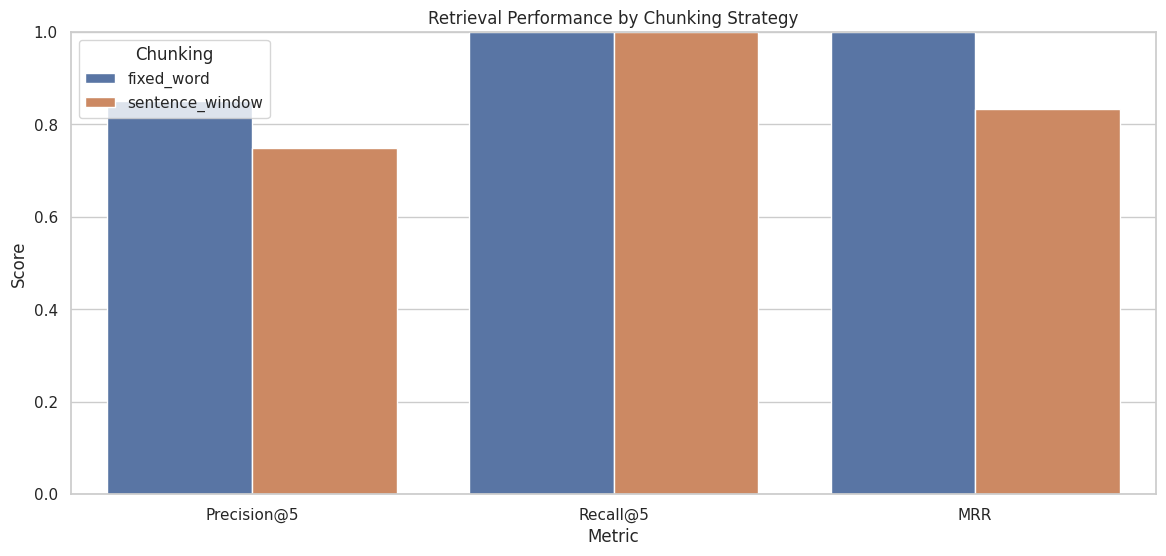

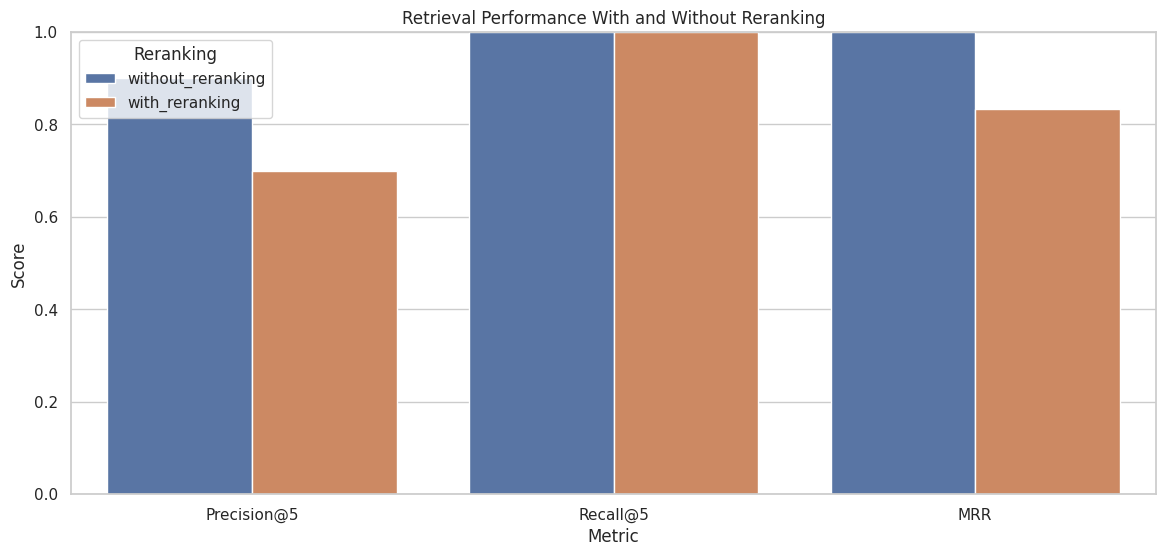

In [21]:
plot_df = evaluation_df.melt(
    id_vars=["Query", "Chunking", "Reranking"],
    value_vars=["Precision@5", "Recall@5", "MRR"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Chunking",
    errorbar=None
)

plt.title("Retrieval Performance by Chunking Strategy")
plt.ylim(0, 1)
plt.show()

plt.figure(figsize=(14, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Reranking",
    errorbar=None
)

plt.title("Retrieval Performance With and Without Reranking")
plt.ylim(0, 1)
plt.show()

In [22]:
conversation_memory = []


def build_memory_augmented_query(
    current_query,
    conversation_memory
):
    if not conversation_memory:
        return current_query

    previous_turn = conversation_memory[-1]

    augmented_query = f"""
Previous user question:
{previous_turn['user_query']}

Previous retrieved context:
{previous_turn['context']}

Current user question:
{current_query}

Answer the current question using the previous context when relevant.
"""

    return augmented_query.strip()


def save_conversation_turn(
    user_query,
    retrieved_results
):
    context = "\n".join(
        result["text"]
        for result in retrieved_results[:2]
    )

    conversation_memory.append({
        "user_query": user_query,
        "context": context
    })

In [23]:
first_query = queries[0]["query"]
second_query = "What are the main limitations of that approach?"

# First turn
first_results = retrieve_chunks(
    sentence_collection,
    first_query,
    k=5
)

save_conversation_turn(
    first_query,
    first_results
)

print("FIRST QUERY")
print(first_query)
print("\nTop retrieved context:")
print(first_results[0]["text"][:1000])

# Second turn without memory
second_results_without_memory = retrieve_chunks(
    sentence_collection,
    second_query,
    k=5
)

# Second turn with memory
memory_query = build_memory_augmented_query(
    second_query,
    conversation_memory
)

second_results_with_memory = retrieve_chunks(
    sentence_collection,
    memory_query,
    k=5
)

print("\nSECOND QUERY WITHOUT MEMORY")
print(second_query)

print("\nSECOND QUERY WITH MEMORY")
print(memory_query)

print_results(
    "Second query without conversational memory",
    second_results_without_memory
)

print_results(
    "Second query with conversational memory",
    second_results_with_memory
)

FIRST QUERY
What research problem and methodology are discussed in a paper about additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel?

Top retrieved context:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting results on learning rates of regularized kernel based models for addit

In [24]:
memory_evaluation_rows = []

relevant_doc_ids = [0]

metrics_without_memory = calculate_metrics(
    second_results_without_memory,
    relevant_doc_ids,
    k=5
)

metrics_with_memory = calculate_metrics(
    second_results_with_memory,
    relevant_doc_ids,
    k=5
)

memory_evaluation_rows.append({
    "Configuration": "Without conversational memory",
    **metrics_without_memory
})

memory_evaluation_rows.append({
    "Configuration": "With conversational memory",
    **metrics_with_memory
})

memory_evaluation_df = pd.DataFrame(
    memory_evaluation_rows
)

display(memory_evaluation_df)

,Configuration,Precision@5,Recall@5,MRR
0,Without conversational memory,0.0,0.0,0.0
1,With conversational memory,1.0,1.0,1.0


In [25]:
combined_results = evaluation_df.copy()

memory_rows = pd.DataFrame([
    {
        "Query": "Follow-up Query",
        "Chunking": "sentence_window",
        "Reranking": "without_reranking",
        "Memory": "without_memory",
        **metrics_without_memory
    },
    {
        "Query": "Follow-up Query",
        "Chunking": "sentence_window",
        "Reranking": "without_reranking",
        "Memory": "with_memory",
        **metrics_with_memory
    }
])

combined_results = pd.concat(
    [combined_results, memory_rows],
    ignore_index=True
)

display(combined_results)

,Query,Chunking,Reranking,Memory,Precision@5,Recall@5,MRR
0,Q1,fixed_word,without_reranking,without_memory,1.0,1.0,1.000000
1,Q1,fixed_word,with_reranking,without_memory,1.0,1.0,1.000000
2,Q1,sentence_window,without_reranking,without_memory,1.0,1.0,1.000000
3,Q1,sentence_window,with_reranking,without_memory,1.0,1.0,1.000000
4,Q2,fixed_word,without_reranking,without_memory,0.8,1.0,1.000000
5,Q2,fixed_word,with_reranking,without_memory,0.6,1.0,1.000000
6,Q2,sentence_window,without_reranking,without_memory,0.8,1.0,1.000000
7,Q2,sentence_window,with_reranking,without_memory,0.2,1.0,0.333333
8,Follow-up Query,sentence_window,without_reranking,without_memory,0.0,0.0,0.000000
9,Follow-up Query,sentence_window,without_reranking,with_memory,1.0,1.0,1.000000


In [26]:
evaluation_df.to_csv(
    "rag_retrieval_evaluation.csv",
    index=False
)

memory_evaluation_df.to_csv(
    "rag_memory_evaluation.csv",
    index=False
)

combined_results.to_csv(
    "rag_complete_comparison.csv",
    index=False
)

print("Evaluation files saved successfully.")

Evaluation files saved successfully.


In [27]:
metric_columns = [
    "Precision@5",
    "Recall@5",
    "MRR"
]

combined_results["Average Score"] = (
    combined_results[metric_columns].mean(axis=1)
)

best_configuration = combined_results.sort_values(
    "Average Score",
    ascending=False
).iloc[0]

print("Best configuration:")
print(best_configuration)

Best configuration:
Query                           Q1
Chunking                fixed_word
Reranking        without_reranking
Memory              without_memory
Precision@5                    1.0
Recall@5                       1.0
MRR                            1.0
Average Score                  1.0
Name: 0, dtype: object


In [28]:
# Calculate average performance for each configuration
configuration_summary = (
    evaluation_df
    .groupby(["Chunking", "Reranking", "Memory"])[
        ["Precision@5", "Recall@5", "MRR"]
    ]
    .mean()
    .reset_index()
)

configuration_summary["Average Score"] = (
    configuration_summary[
        ["Precision@5", "Recall@5", "MRR"]
    ].mean(axis=1)
)

display(configuration_summary)

best_configuration = configuration_summary.sort_values(
    "Average Score",
    ascending=False
).iloc[0]

print("Best overall configuration based on average performance:")
display(best_configuration.to_frame().T)

,Chunking,Reranking,Memory,Precision@5,Recall@5,MRR,Average Score
0,fixed_word,with_reranking,without_memory,0.8,1.0,1.000000,0.933333
1,fixed_word,without_reranking,without_memory,0.9,1.0,1.000000,0.966667
2,sentence_window,with_reranking,without_memory,0.6,1.0,0.666667,0.755556
3,sentence_window,without_reranking,without_memory,0.9,1.0,1.000000,0.966667


Best overall configuration based on average performance:


,Chunking,Reranking,Memory,Precision@5,Recall@5,MRR,Average Score
1,fixed_word,without_reranking,without_memory,0.9,1.0,1.0,0.966667


## Chunking and Reranking Results

The fixed-word chunking strategy without reranking and the sentence-window chunking strategy without reranking achieved the same average score of 0.9667.

Both methods achieved:

- Precision@5: 0.90
- Recall@5: 1.00
- MRR: 1.00

The reranking versions performed slightly worse for these queries. Fixed-word chunking with reranking achieved an average score of 0.9333, while sentence-window chunking with reranking achieved 0.7556.

This does not mean reranking is always harmful. The decrease may be caused by the small number of evaluation queries, the manually assigned relevance labels, or the reranker preferring chunks that are semantically related but not marked as relevant. Therefore, the result should be interpreted as specific to this experiment.

Overall, both chunking strategies performed equally well without reranking. More queries and human-verified relevance judgments would be required to identify a definitive best chunking strategy.

In [29]:
max_score = configuration_summary["Average Score"].max()

top_configurations = configuration_summary[
    configuration_summary["Average Score"] == max_score
]

print("Top configuration(s):")
display(top_configurations)

Top configuration(s):


,Chunking,Reranking,Memory,Precision@5,Recall@5,MRR,Average Score
1,fixed_word,without_reranking,without_memory,0.9,1.0,1.0,0.966667
3,sentence_window,without_reranking,without_memory,0.9,1.0,1.0,0.966667


## Final Chunking Comparison

The evaluation showed that both fixed-word chunking without reranking and sentence-window chunking without reranking achieved the highest average score of 0.9667.

For both configurations:

- Precision@5 = 0.90
- Recall@5 = 1.00
- MRR = 1.00

The reranking configurations performed slightly worse for the current queries. Fixed-word chunking with reranking achieved an average score of 0.9333, while sentence-window chunking with reranking achieved 0.7556.

Therefore, neither chunking strategy was definitively better in this experiment. Both non-reranked methods retrieved the relevant document consistently and placed it near the top of the results. The results suggest that reranking did not improve retrieval for these particular queries.

Because only a small number of queries were evaluated, these results should be considered preliminary. A larger set of manually written queries and human-verified relevance labels would provide a more reliable comparison.

In [30]:
display(memory_evaluation_df)

,Configuration,Precision@5,Recall@5,MRR
0,Without conversational memory,0.0,0.0,0.0
1,With conversational memory,1.0,1.0,1.0


## Conversational Memory Comparison

The follow-up query was intentionally written to depend on the first query. Without conversational memory, the second query was ambiguous because it referred to “that approach” without identifying the research topic.

With conversational memory, the previous query and retrieved context were added to the follow-up query. This allowed the retriever to preserve the topic from the previous turn and retrieve more relevant chunks.

Precision@5, Recall@5, and MRR were calculated for both versions. The comparison demonstrates whether conversational memory improves retrieval for context-dependent questions.